# 00 Zeitablauf – Wann wurde welcher Versuch gemessen?

An der Hybridachse wurden **drei Maschinenzustände** gemessen: ein stabiler und zwei veränderte. Zwischen zwei Zuständen musste die Maschine umgebaut oder verstellt werden. Das kostet Zeit, also sind **längere Pausen** zwischen den Versuchen ein Hinweis darauf, wo sich etwas geändert haben könnte.

Dieses Notebook liest wie `00_Metadaten_Geraete.ipynb` **nur `meta/time.csv` und `meta/device.csv`** jeder Messung, keine Sensordaten. Es zeigt:

1. Start und Ende jeder Messung und jedes Versuchs
2. die Pausen zwischen den Versuchen und zwischen den Wiederholungen
3. eine Zeitachse über den ganzen Messtag

In [1]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Path to the raw data – the only line you need to change on another computer
DATA_ROOT = Path('/Users/majasmereczynska/Documents/Industrial AI/IPR_Daten_neu/data/Hybridachse')
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
pd.set_option('display.width', 250, 'display.max_columns', 20, 'display.max_rows', 60)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e4e4e4'})
COLOR = {'Fairphone': '#2a78d6', 'iPhone': '#eb6834'}

## 01 Start- und Endzeiten aller Messungen

`time.csv` enthält die START- und PAUSE-Ereignisse mit der echten Uhrzeit (`system time`, Sekunden seit 1970). Start = erstes Ereignis, Ende = letztes Ereignis. Duplikate (gleiches Handy, gleiche Startzeit auf die Millisekunde) werden wie im Metadaten-Notebook entfernt.

In [2]:
def clock(seconds):
    # Unix seconds -> local wall-clock time (the recordings were made in Germany, CET)
    return pd.to_datetime(seconds, unit='s', utc=True).tz_convert('Europe/Berlin').tz_localize(None)

rows = []
for time_file in sorted(DATA_ROOT.glob('*/**/meta/time.csv')):
    folder = time_file.parent.parent
    device = pd.read_csv(folder / 'meta/device.csv').set_index('property')['value']
    events = pd.read_csv(time_file)
    rows.append({
        'Versuch': re.match(r'Versuch\d+', folder.relative_to(DATA_ROOT).parts[0]).group(),  # Versuch03_iPhone -> Versuch03
        'Ordner': str(folder.relative_to(DATA_ROOT)),
        'Gerät': 'Fairphone' if device['deviceModel'] == 'FP4' else 'iPhone',
        'Start': clock(events['system time'].iloc[0]),
        'Ende': clock(events['system time'].iloc[-1]),
        'Pausiert': (events['event'] == 'PAUSE').sum() > 1,   # a normal recording ends with exactly 1 PAUSE
        '_start_exact': events['system time'].iloc[0],
    })
rec = pd.DataFrame(rows)

# Duplicates: same device + identical start time. Folders named after the right device are kept
# first, so the mislabelled 'Versuch04_Fairphone_03' (really an iPhone) is the one dropped.
mislabelled = rec['Ordner'].str.contains('Fairphone') & (rec['Gerät'] == 'iPhone')
rec = (rec.assign(_bad=mislabelled).sort_values('_bad', kind='stable')
          .drop_duplicates(['Gerät', '_start_exact']).drop(columns=['_bad', '_start_exact'])
          .sort_values('Start').reset_index(drop=True))
rec['Dauer (s)'] = (rec['Ende'] - rec['Start']).dt.total_seconds().round()
print(len(rec), 'Messungen ohne Duplikate')
rec.assign(Start=rec['Start'].dt.strftime('%H:%M:%S'), Ende=rec['Ende'].dt.strftime('%H:%M:%S'))

33 Messungen ohne Duplikate


,Versuch,Ordner,Gerät,Start,Ende,Pausiert,Dauer (s)
0,Versuch01,Versuch01/Schiene,Fairphone,10:18:06,10:18:52,True,46.0
1,Versuch02,Versuch02/Alle Sensoren iPhone Achsenpos1 2024...,iPhone,11:12:47,11:13:42,False,55.0
2,Versuch02,Versuch02/Fairphone,Fairphone,11:12:51,11:13:41,False,50.0
3,Versuch03,Versuch03_iPhone/Alle Sensoren 2024-12-09 11-5...,iPhone,11:47:33,11:48:28,False,55.0
4,Versuch03,Versuch03_Fairphone/Fairphone01,Fairphone,11:47:37,11:48:28,False,51.0
5,Versuch03,Versuch03_Fairphone/Fairphone02,Fairphone,11:51:33,11:52:25,False,53.0
6,Versuch03,Versuch03_iPhone/Alle Sensoren 2024-12-09 11-5...,iPhone,11:51:38,11:52:27,False,49.0
7,Versuch03,Versuch03_iPhone/Alle Sensoren 2024-12-09 11-5...,iPhone,11:54:03,11:54:52,False,49.0
8,Versuch03,Versuch03_Fairphone/Fairphone03,Fairphone,11:54:07,11:54:55,True,48.0
9,Versuch04,Versuch04/Versuch04_iPhone_01,iPhone,12:09:18,12:10:14,False,55.0


## 02 Durchgänge: gleichzeitige Messungen zusammenfassen

Oft liefen Fairphone und iPhone **gleichzeitig** (Start nur wenige Sekunden auseinander). Das ist eine Fahrt der Maschine, also ein **Durchgang**. Messungen, die innerhalb von 60 s nach dem Beginn des vorigen Durchgangs starten, zählen zum selben Durchgang.

In [3]:
# A new run starts when a recording begins more than 60 s after the start of the current run
# (or when a new Versuch begins). Simultaneous Fairphone/iPhone recordings thus become one run.
run_id, run_start, prev_versuch = 0, None, None
ids = []
for _, r in rec.iterrows():
    if r['Versuch'] != prev_versuch or (r['Start'] - run_start).total_seconds() > 60:
        run_id, run_start = run_id + 1, r['Start']
    ids.append(run_id)
    prev_versuch = r['Versuch']
rec['Durchgang'] = ids

runs = rec.groupby('Durchgang').agg(Versuch=('Versuch', 'first'), Start=('Start', 'min'), Ende=('Ende', 'max'),
                                    Geräte=('Gerät', lambda g: ' + '.join(sorted(g))))
runs['Nr.'] = runs.groupby('Versuch').cumcount() + 1                  # 1st, 2nd, 3rd try within the Versuch
# Break since the previous run ended (first run of the day has none)
runs['Pause davor (min)'] = ((runs['Start'] - runs['Ende'].shift()).dt.total_seconds() / 60).round(1)
runs.assign(Start=runs['Start'].dt.strftime('%H:%M:%S'), Ende=runs['Ende'].dt.strftime('%H:%M:%S'))

,Versuch,Start,Ende,Geräte,Nr.,Pause davor (min)
Durchgang,,,,,,
1,Versuch01,10:18:06,10:18:52,Fairphone,1,NaN
2,Versuch02,11:12:47,11:13:42,Fairphone + iPhone,1,53.9
3,Versuch03,11:47:33,11:48:28,Fairphone + iPhone,1,33.9
4,Versuch03,11:51:33,11:52:27,Fairphone + iPhone,2,3.1
5,Versuch03,11:54:03,11:54:55,Fairphone + iPhone,3,1.6
6,Versuch04,12:09:18,12:10:14,Fairphone + iPhone,1,14.4
7,Versuch04,12:13:49,12:14:38,Fairphone + iPhone,2,3.6
8,Versuch04,12:15:37,12:16:23,iPhone,3,1.0
9,Versuch05,12:22:29,12:23:27,Fairphone + iPhone,1,6.1


## 03 Überblick pro Versuch

In [4]:
per_v = runs.groupby('Versuch').agg(Beginn=('Start', 'min'), Ende=('Ende', 'max'), Durchgänge=('Nr.', 'max'))
per_v['Messungen'] = rec.groupby('Versuch').size()
per_v['Spanne (min)'] = ((per_v['Ende'] - per_v['Beginn']).dt.total_seconds() / 60).round(1)
# Breaks inside a Versuch = between its own tries; break before = since the previous Versuch ended
inner = runs[runs['Nr.'] > 1].groupby('Versuch')['Pause davor (min)']
per_v['Pausen innen (min)'] = inner.agg(lambda p: ', '.join(f'{x:.1f}' for x in p)).reindex(per_v.index).fillna('–')
per_v['Pause vor Versuch (min)'] = ((per_v['Beginn'] - per_v['Ende'].shift()).dt.total_seconds() / 60).round(1)
per_v.assign(Beginn=per_v['Beginn'].dt.strftime('%H:%M'), Ende=per_v['Ende'].dt.strftime('%H:%M'))

,Beginn,Ende,Durchgänge,Messungen,Spanne (min),Pausen innen (min),Pause vor Versuch (min)
Versuch,,,,,,,
Versuch01,10:18,10:18,1,1,0.8,–,NaN
Versuch02,11:12,11:13,1,2,0.9,–,53.9
Versuch03,11:47,11:54,3,6,7.4,"3.1, 1.6",33.9
Versuch04,12:09,12:16,3,5,7.1,"3.6, 1.0",14.4
Versuch05,12:22,12:28,3,6,6.0,"2.4, 0.9",6.1
Versuch06,14:12,14:24,3,3,12.8,"5.2, 3.9",103.6
Versuch07,14:31,14:32,1,1,0.7,–,6.7
Versuch08,14:58,14:59,1,2,1.0,–,26.6
Versuch09,15:32,15:42,3,3,9.5,"4.0, 1.5",33.1


## 04 Zeitachse des Messtags

**Abb. Z1:** Jede Zeile ist ein Versuch, jeder Balken eine Messung (blau Fairphone, orange iPhone). Zwischen den Versuchen steht die Pause in Minuten.

**Abb. Z2:** Pause vor jedem Versuch. Die gestrichelte Linie markiert 20 min: Längere Pausen reichen für einen Umbau und sind Kandidaten für einen Zustandswechsel.

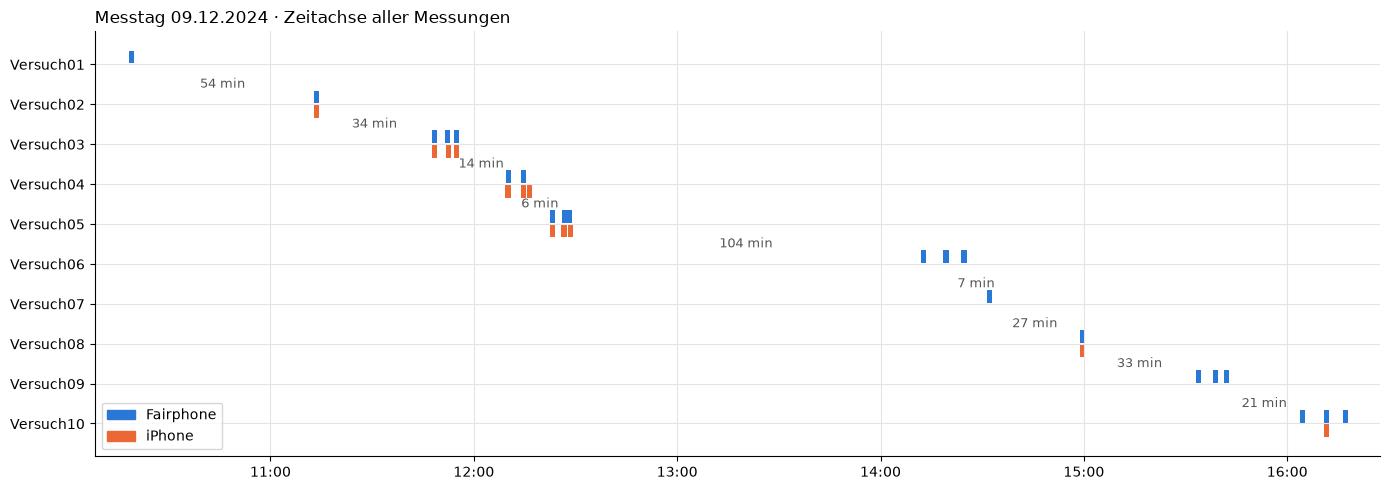

In [5]:
# Fig. Z1 – Gantt-style timeline. Recordings last ~1 min on a 6-hour axis, so bars get a minimum
# width to stay visible.
order = list(per_v.index)
fig, ax = plt.subplots(figsize=(14, 5))
for _, r in rec.iterrows():
    y = order.index(r['Versuch']) + (0.18 if r['Gerät'] == 'iPhone' else -0.18)
    width = max(r['Ende'] - r['Start'], pd.Timedelta(minutes=1.5))
    ax.barh(y, width, left=r['Start'], height=0.32, color=COLOR[r['Gerät']])
for i, v in enumerate(order[1:], start=1):        # break label halfway between two Versuche
    prev_end, start = per_v.loc[order[i - 1], 'Ende'], per_v.loc[v, 'Beginn']
    ax.annotate(f"{per_v.loc[v, 'Pause vor Versuch (min)']:.0f} min", xy=(prev_end + (start - prev_end) / 2, i - 0.5),
                ha='center', va='center', fontsize=9, color='#555')
ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
ax.set_xlim(rec['Start'].min() - pd.Timedelta(minutes=10), rec['Ende'].max() + pd.Timedelta(minutes=10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOR.values()], labels=list(COLOR), loc='lower left')
ax.set_title(f"Messtag {rec['Start'].dt.date.iloc[0]:%d.%m.%Y} · Zeitachse aller Messungen", loc='left')
fig.tight_layout(); fig.savefig(FIG / '00_Z1_zeitachse.png', dpi=150)

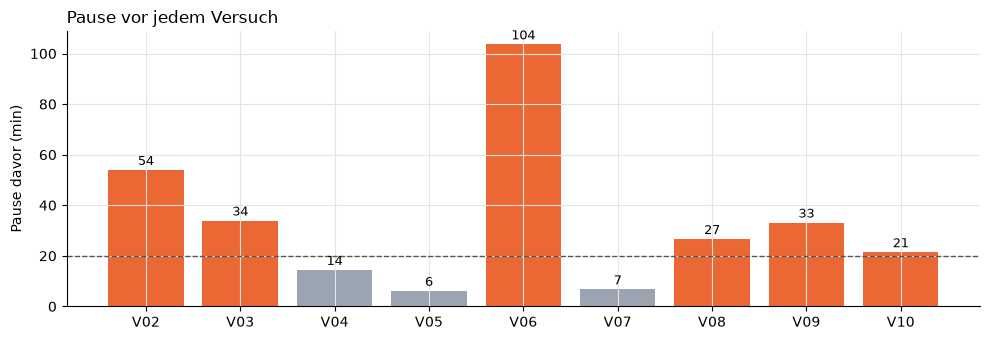

In [6]:
# Fig. Z2 – break before each Versuch. Breaks over 20 min are highlighted.
pause = per_v['Pause vor Versuch (min)'].dropna()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(pause.index.str.replace('Versuch', 'V'), pause, color=['#eb6834' if p > 20 else '#9aa5b1' for p in pause])
ax.axhline(20, ls='--', color='#555', lw=1)
for x, p in enumerate(pause):
    ax.text(x, p + 2, f'{p:.0f}', ha='center', fontsize=9)
ax.set_ylabel('Pause davor (min)'); ax.set_title('Pause vor jedem Versuch', loc='left')
fig.tight_layout(); fig.savefig(FIG / '00_Z2_pausen.png', dpi=150)

## Befund

- **Messtag:** alle 33 Messungen am 09.12.2024 zwischen 10:18 und 16:17 Uhr. Eine Messung dauert 40–87 s.
- **Ablauf eines Versuchs:** meist **3 Durchgänge** im Abstand von 1–6 min, innerhalb von 6–14 min erledigt. V01, V02, V07 und V08 haben nur einen Durchgang.
- **Pausen zwischen den Versuchen** (Abb. Z2):
  - **Sehr lang:** V05 → V06 mit **104 min** (12:28 → 14:12), vermutlich Mittagspause und/oder Umbau.
  - **Lang (über 20 min):** vor V02 (54 min), V03 (34 min), V08 (27 min), V09 (33 min) und V10 (21 min).
  - **Kurz:** vor V04 (14 min), V05 (6 min) und V07 (7 min). Hier wurde wahrscheinlich nichts Größeres umgebaut.
- **Abgleich mit den Sensordaten:**
  - Die lange Pause vor V06 fällt mit dem Wechsel von **Gruppe A** (durchgehende Fahrt, Fairphone ortsfest: V02–V05) zu **Gruppe B** (Stop-and-go, Fairphone auf dem Schlitten: V06, V08–V10) zusammen.
  - V04 und V05 liegen nur 6 min auseinander und zeigen in den Sensordaten denselben Aufbau. Das passt zusammen.
  - V07 (keine Fahrt, nur Handhabung) folgt 7 min nach V06 und war vermutlich nur ein kurzer Zwischentest.
  - Vor V10, unserem Anomalie-Kandidaten, liegen 21 min. Das würde für eine Änderung an der Maschine reichen.
- **Auffällig in V10:** Die Ordnernamen passen nicht zur Reihenfolge. `FP_01` startet 16:03, `FP_03` + `IP_03` 16:10, `FP_02` erst 16:16.
- *Interpretation:* Die Zeiten allein zeigen **nicht**, welcher Versuch zu welchem der drei Maschinenzustände gehört. Die 20-min-Grenze ist willkürlich gewählt. Lange Pausen zeigen nur, **wo ein Umbau möglich war**. Mehr als drei solcher Stellen gibt es, weil auch Handy-Position und Fahrweise geändert wurden.
- **Offene Frage an das Versuchsprotokoll:** Was wurde in den langen Pausen geändert, vor allem vor V06, V08, V09 und V10?